# Lab Assignment 3
### MPATE-GE 2598 Fundamentals of Digital Signal Theory Lab

In this lab assignment, you will synthesize signals using wave generators and plot their waveforms.

## Background

**Sine Wave**:
$y(t) = \sin(\omega_0 t + \phi)$

Complex periodic waveforms can be constructed by adding a series of sine waves of frequencies that are mathematically related to each other.

The summation formulae for square, triangle, and sawtooth waves are:

**Square Wave**:

$y(t) = \sum_{k=1}^{k_{max}} \frac{1}{k} \sin(k\omega_0t)$ where $k$ is odd.

**Triangle Wave**:

$y(t) = \sum_{k=1}^{k_{max}} (-1)^{(k-1)/2} \frac{1}{k^2} \sin(k\omega_0t)$ where $k$ is odd.

**Sawtooth Wave**:

$y(t) = - \sum_{k=1}^{k_{max}} \frac{1}{k} \sin(k\omega_0t)$

**Note**: $\omega_0 = 2\pi f_0$

**Import Libraries**

In [1]:
import numpy as np
import soundfile as sf
from IPython.display import Audio
import matplotlib.pyplot as plt

## Part 1: Signal Generation

Fill in the skeleton code functions to address the tasks marked in each of them.


**Note**:
When selecting odd overtones, make sure you process the correct amount of odd overtones corresponding to `num_overtones` instead of stopping the function at the overtone count equal to `num_overtones`. 

For example, if we want 3 odd overtones, we need to stop the loop at overtone 7 ($f_0 + f_3 + f_5 + f_7$), not at overtone 3 ($f_0 + f_3$).

### 1.1 `sinewave()`

The function below is incomplete. Fill in the missing lines of code to generate the `time_vector` and `signal`.

In [2]:
def sinewave(fs, duration, f0, phi):
    '''Generate a sine wave.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f0 : The fundamental frequency (in Hz)

    phi : The phase of the signal (in radians)
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized sine wave
    '''
    time_vector = np.linspace(0, duration, fs*duration)
    
    signal = np.sin(2*np.pi*f0*time_vector + phi)
    
    return time_vector, signal

### 1.2 `cosinewave()`

Copy and paste the code from your `sinewave()` function here. Modify it to generate a cosine wave **without using** `np.cos()`. You may only use `np.sin()`.

In [3]:
def cosinewave(fs, duration, f0, phi):
    '''Generate a cosine wave.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f0 : The fundamental frequency (in Hz)
    
    phi : The phase of the signal (in radians)
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized cosine wave
    '''
    # YOUR CODE HERE
    time_vector = np.linspace(0, duration, fs*duration)
    
    signal = np.sin(2*np.pi*f0*time_vector + phi + np.pi*1/2)

    return time_vector, signal

### 1.3 `squarewave()`

The code for generating a square wave has been provided for you. Modify the function so that no aliased overtones are present in the output signal. Add comments to your function to explain what your code is doing to address aliasing.

In [4]:
def squarewave(fs, duration, f0, num_overtones):
    '''Generate a square wave.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f0 : The fundamental frequency (in Hz)

    num_overtones : The number of odd overtones
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized square wave
    '''
    # Modify the following code so that no aliased overtones
    # are present in the signal.

    time_vector = np.arange(0, duration, 1/fs)
    signal = np.zeros(len(time_vector))

    nyquist = fs / 2
    for k in range(1, 2 * (num_overtones + 1), 2):
        if k * f0 <= nyquist:
            signal += np.sin(k * 2 * np.pi * f0 * time_vector) / k
    
    return time_vector, signal

### 1.4 `triangularwave()`

(a) The provided code is **not** functional. Address the problems so that the function operates correctly. Do not rewrite the entire function; the basic functionality of the code must remain the same.

**Triangle Wave**:

$y(t) = \sum_{k=1}^{k_{max}} (-1)^{(k-1)/2} \frac{1}{k^2} \sin(k\omega_0t)$ where $k$ is odd.

In [5]:
def triangularwave(fs, duration, f0, num_overtones):
    '''Generate a triangular wave.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f0 : The fundamental frequency (in Hz)

    num_overtones : The number of odd overtones
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized triangular wave
    '''
    # Address the problems in the code below.
    # Then, in part (b), comment what problems the function had and how they were fixed.
    # Do not change the basic operation of the function.

    time_vector = np.arange(0, duration, 1/fs)
    signal = np.zeros(len(time_vector))
    
    i = 0
    k = 1
    
    while i <= num_overtones:
        signal += ((-1)**((k-1)/2)) * np.sin(2 * np.pi * f0 * k * time_vector) / k**2
        i += 1
        k += 2
        
    return time_vector, signal 

(b) Discuss what changes you made and why they were necessary in context of the triangle wave.

**Answer**: YOUR ANSWER HERE

### 1.5 `sawtoothwave()`

You have been provided the function for generating a sawtooth wave.

**Sawtooth Wave**:

$y(t) = - \sum_{k=1}^{k_{max}} \frac{1}{k} \sin(k\omega_0t)$

In [6]:
def sawtoothwave(fs, duration, f0, num_overtones):
    '''Generate a sawtooth wave.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f0 : The fundamental frequency (in Hz)

    num_overtones : The number of overtones
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized sawtooth wave
    '''
    time_vector = np.arange(0, duration, 1/fs)
    
    signal = np.zeros(duration * fs)

    k = 1

    # while k <= (num_overtones + 1):
    #     signal -= np.sin(2 * np.pi * f0 * k * time_vector) / k
    #     k += 1

    for k in range (1, num_overtones + 2):
        signal -= np.sin(2 * np.pi * f0 * k * time_vector) / k

    return time_vector, signal

(a) Answer the following questions about the function.

(i) Why is the hop / step size for the time vector `1/fs`?

**Answer**: YOUR ANSWER HERE

(ii) What are the units of `duration * sr`?

**Answer**: YOUR ANSWER HERE

(iii) Why is the `while` loop `<=` and why does it require a `+ 1`?

**Answer**: YOUR ANSWER HERE

(iv) The formula includes a negative sign in the summation. What would be the result if the sign was removed?

**Answer**: YOUR ANSWER HERE

(b) Return to the function and replace the `while` loop with a `for` loop.

## Part 2: Plot and Playback

You should utilize **each function** above to generate and display one of each of the signal types. Each generated signal should be played back using the `Audio` function. Remember to use the correct sampling rate during playback. You may choose any inputs that you would like.

The plots must show amplitude vs. time (not samples). In order to make the waveforms visible and clear, **plot only four (4) periods of each signal**. Make sure you label your plot.

**Important**: Use `plt.xlim()` and the relationship between period and the fundamental frequency to limit the time axis; do not hard code it. If a different frequency is selected, the graph must also display four cycles of the waveform.

### 2.1 Sine Wave

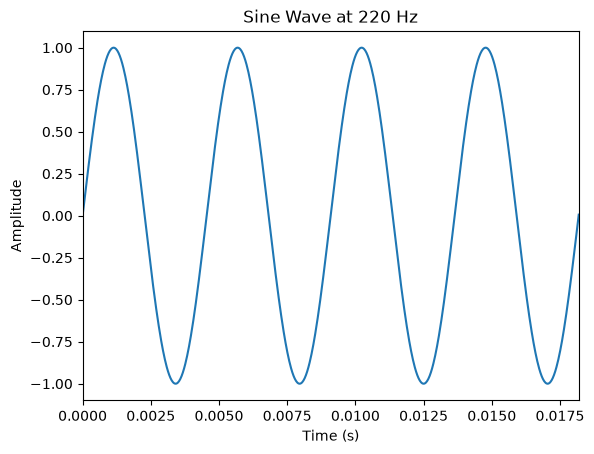

In [12]:
# YOUR CODE HERE
fs = 44100
duration = 1
f0 = 220
t, signal = sinewave(fs, duration, f0, phi = 0)

T = 1 / f0
plt.plot(t, signal)
plt.xlim(0, 4 * T)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Sine Wave at {f0} Hz')
plt.show()

Audio(signal, rate=fs)

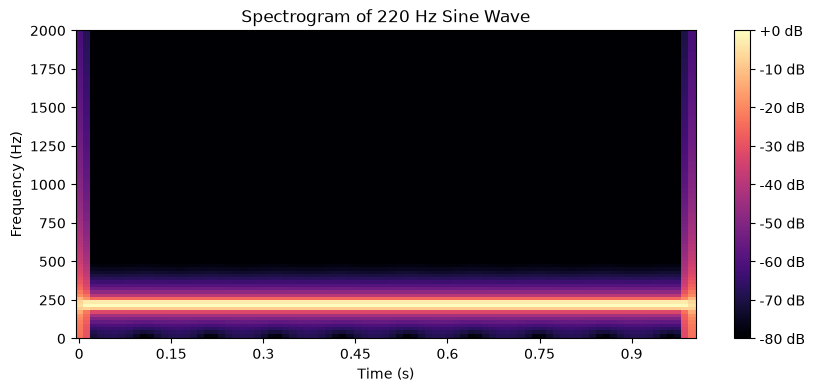

In [13]:
import librosa.display

# Compute the short-time Fourier transform of the sine wave
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)),
    ref=np.max
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    D,
    sr=fs,
    x_axis='time',
    y_axis='linear'
)
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 2000)
plt.title(f'Spectrogram of {f0} Hz Sine Wave')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

### 2.2 Cosine Wave

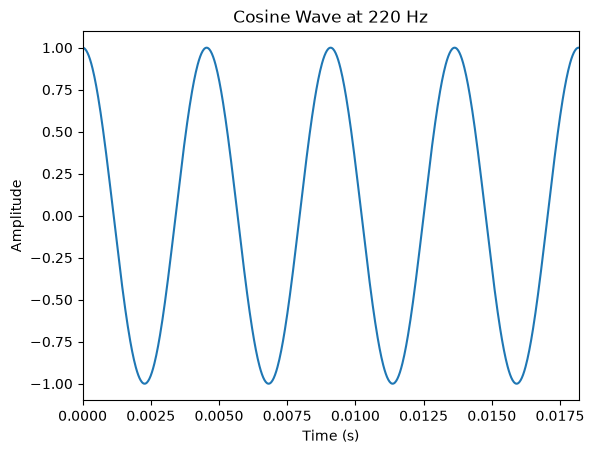

In [15]:
# YOUR CODE HERE
fs = 44100
duration = 1
f0 = 220
t, signal = cosinewave(fs, duration, f0, phi = 0)

T = 1 / f0
plt.plot(t, signal)
plt.xlim(0, 4 * T)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Cosine Wave at {f0} Hz')
plt.show()

Audio(signal, rate=fs)

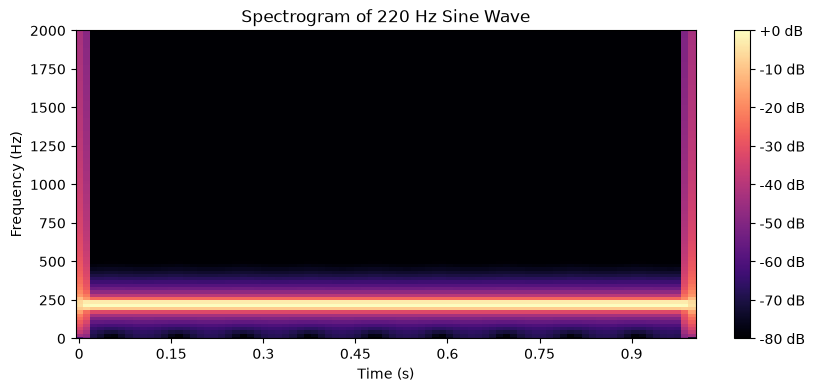

In [16]:
import librosa.display

# Compute the short-time Fourier transform of the sine wave
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)),
    ref=np.max
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    D,
    sr=fs,
    x_axis='time',
    y_axis='linear'
)
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 2000)
plt.title(f'Spectrogram of {f0} Hz Sine Wave')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

### 2.3 Square Wave

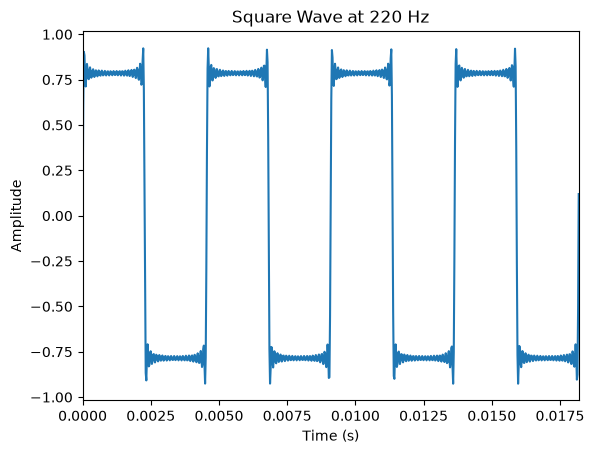

In [17]:
# YOUR CODE HERE
fs = 44100
duration = 1
f0 = 220
t, signal = squarewave(fs, duration, f0, num_overtones=20)

T = 1 / f0
plt.plot(t, signal)
plt.xlim(0, 4 * T)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Square Wave at {f0} Hz')
plt.show()

Audio(signal, rate=fs)

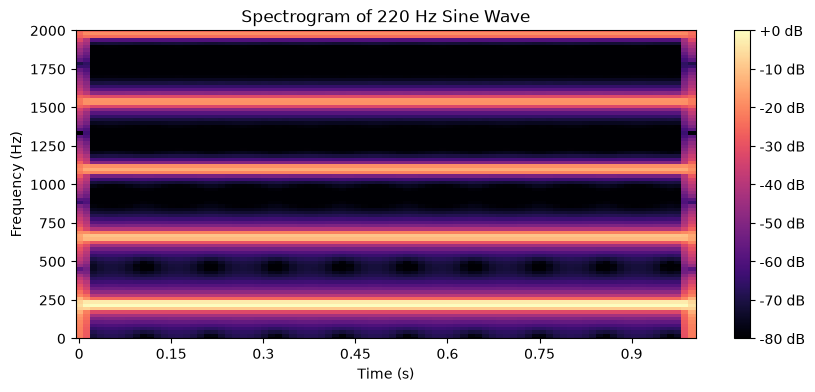

In [18]:
import librosa.display

# Compute the short-time Fourier transform of the sine wave
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)),
    ref=np.max
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    D,
    sr=fs,
    x_axis='time',
    y_axis='linear'
)
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 2000)
plt.title(f'Spectrogram of {f0} Hz Sine Wave')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

### 2.4 Triangle Wave

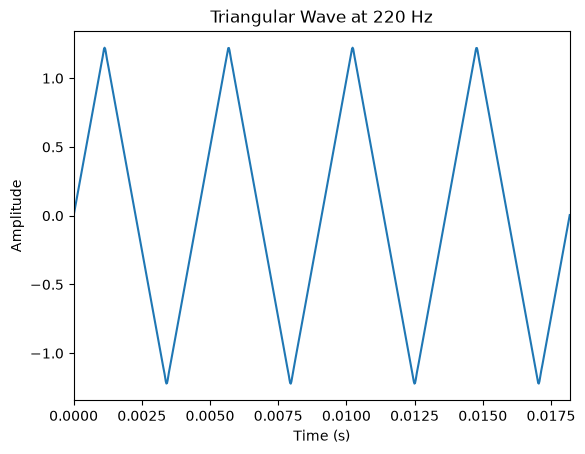

In [19]:
# YOUR CODE HERE
fs = 44100
duration = 1
f0 = 220
t, signal = triangularwave(fs, duration, f0, num_overtones=20)

T = 1 / f0
plt.plot(t, signal)
plt.xlim(0, 4 * T)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Triangular Wave at {f0} Hz')
plt.show()

Audio(signal, rate=fs)

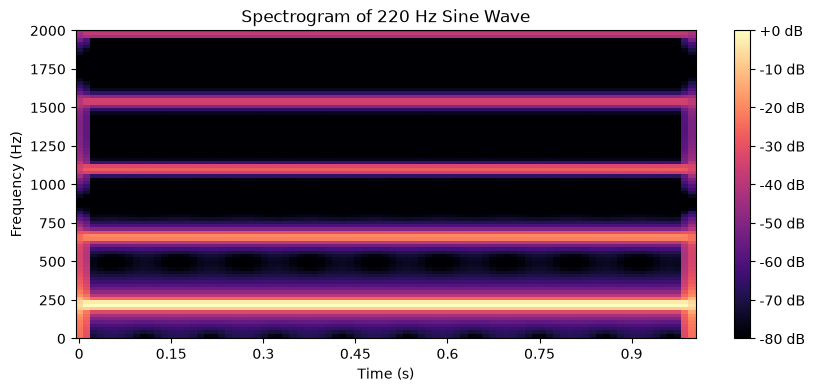

In [20]:
import librosa.display

# Compute the short-time Fourier transform of the sine wave
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)),
    ref=np.max
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    D,
    sr=fs,
    x_axis='time',
    y_axis='linear'
)
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 2000)
plt.title(f'Spectrogram of {f0} Hz Sine Wave')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

### 2.5 Sawtooth Wave

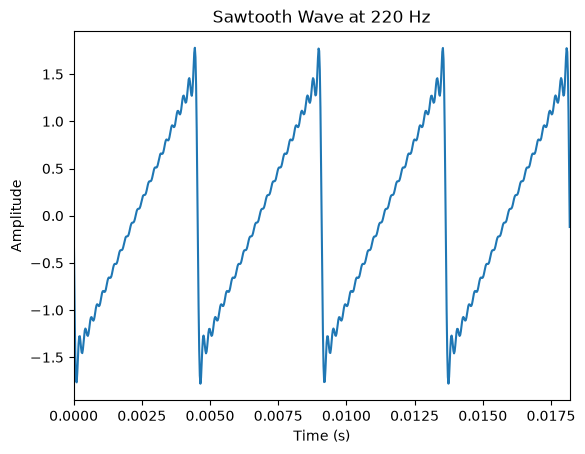

In [21]:
# YOUR CODE HERE
fs = 44100
duration = 1
f0 = 220
t, signal = sawtoothwave(fs, duration, f0, num_overtones=20)

T = 1 / f0
plt.plot(t, signal)
plt.xlim(0, 4 * T)
plt.xlabel('Time (s)')
plt.ylabel('Amplitude')
plt.title(f'Sawtooth Wave at {f0} Hz')
plt.show()

Audio(signal, rate=fs)

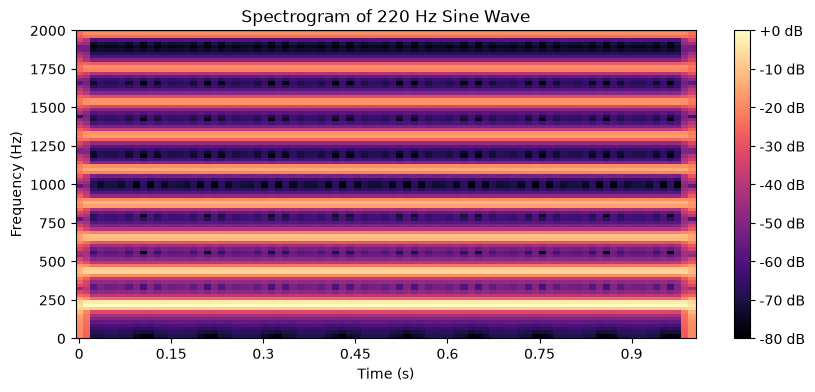

In [22]:
import librosa.display

# Compute the short-time Fourier transform of the sine wave
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(signal)),
    ref=np.max
)

plt.figure(figsize=(10, 4))
librosa.display.specshow(
    D,
    sr=fs,
    x_axis='time',
    y_axis='linear'
)
plt.colorbar(format='%+2.0f dB')
plt.ylim(0, 2000)
plt.title(f'Spectrogram of {f0} Hz Sine Wave')
plt.xlabel('Time (s)')
plt.ylabel('Frequency (Hz)')
plt.show()

## Part 3: Bonus Exercise

A [**pulse wave**](https://en.wikipedia.org/wiki/Pulse_wave) (or pulse train) is a periodic, non-sinusoidal waveform which alternates between a high value representing "on" (e.g., 1) and a low value representing "off" (e.g., 0). The amount of time it spends in the high vs. low state in a single period varies according to its **duty cycle** (a ratio).

You have been provided the skeleton of a pulse wave generator below. Complete the function and include comments explaining the logic your code.

**Note**: You may **not** use an existing signal generator in your function.

In [ ]:
def pulsewave(fs, duration, f, duty):
    '''Generate a pulse wave which oscillates between 0 and 1.

    Parameters
    ----------
    fs : The sampling rate (in Hz)

    duration : The desired length of the
               output signal (in seconds)

    f : The frequency of pulses (in Hz)
    
    duty : The proportion of the period during which
           the signal is "on" (0 ≤ duty ≤ 1)
        
    Returns
    -------
    time_vector : of type np.ndarray
                  The timestamps of each sample

    signal : of type np.ndarray
             The synthesized pulse wave
    '''

    return time_vector, signal

Now, generate a pulse wave with input parameters of your choice, play it back, and plot it so that the waveform is visible.

In [ ]:
# YOUR CODE HERE

---
_End of Lab 4_